In [17]:
#EX 1

import csv
from random import sample

def gen_esantion(fisier, nr_indivizi):

    with open(fisier, "r", encoding="utf-8") as f:
       reader = csv.DictReader(f, skipinitialspace=True)
       studenti = list(reader)


    nu_prezentat = [student for student in studenti
                    if student["Prezentat"] == "Nu"]

    if len(nu_prezentat) < nr_indivizi:
        print(f"Esantion: {nr_indivizi} este mai mare decat totalul de studenti care nu au prezentat!")
        return
    
    esantion = sample(nu_prezentat, nr_indivizi)

    print(f"{nr_indivizi} studenti care nu au prezentat încă o temă: ", esantion)

gen_esantion("lista_studenti.csv", 10)
gen_esantion("lista_studenti.csv", 5)


Esantion: 10 este mai mare decat totalul de studenti care nu au prezentat!
5 studenti care nu au prezentat încă o temă:  [{'Nume': 'Ana Maria', 'Prezentat': 'Nu'}, {'Nume': 'Dan Alin', 'Prezentat': 'Nu'}, {'Nume': 'Pop Gigi', 'Prezentat': 'Nu'}, {'Nume': 'Mirica David', 'Prezentat': 'Nu'}, {'Nume': 'Dascal Liviu', 'Prezentat': 'Nu'}]


#EX 2. a)

P(stema) = P(ban) = 1/2

P(N=1) = P(stema) = 1/2
P(N=2) = P(stema) * P(ban) = 1/2 * 1/2
P(N=3) = P(stema) * P(ban) * P(ban) = 1/2 * 1/2 * 1/2
.
.
.
P(N=n) = P(stema) * P(ban)^(n-1) = 1/2 * (1/2)^(n-1)  = 1/2 * (1 - 1/2)^(n-1) = Geometric(1/2) =>
=> N, numarul de pasi ai jocului, urmeaza o distributie geometrica, cu parametrul p = 1/2; formula: Geometric(p) = (1 - p)^(n-1) * p

In [29]:
#EX 2. b)

import random

def joc(p=0.5):

    N = 0
    S = 0

    while True:
        N += 1

        if random.random() < p:
            z = random.randint(1, 6)
            S += z - 3
            break
        else:
            S -= 0.5

    return N, S


N, S = joc()

print("N: ", N)
print("S: ", S)

N:  1
S:  -1


Media lui S:  0.0111


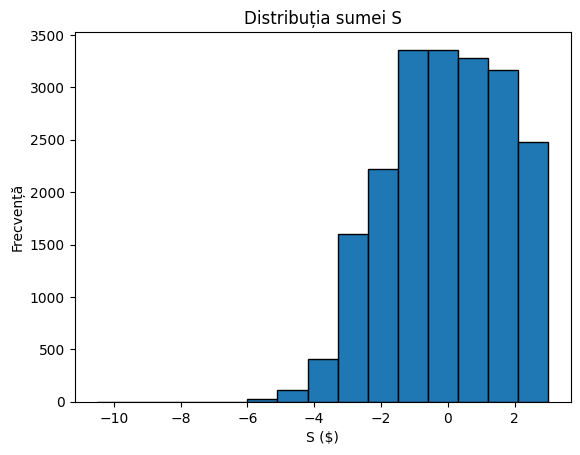

In [ ]:
#EX 2. c)
import matplotlib.pyplot as plt

def sim_jocuri(nr_jocuri, p = 0.5):

    lista_sume = []

    for i in range(nr_jocuri):
        N, S = joc(p)
        lista_sume.append(S)

    return lista_sume

def calcul_medie(lista_sume):

    suma = sum(lista_sume)
    nr_S = len(lista_sume)

    return suma/nr_S

def afis_hist(lista_sume):
    plt.hist(lista_sume, bins=15, edgecolor="black")
    plt.xlabel("S ($)")
    plt.ylabel("Frecvență")
    plt.title("Distribuția sumei S")
    plt.show()


lista_S = sim_jocuri(30000)
print("Media lui S: ", calcul_medie(lista_S))
afis_hist(lista_S)


Cazul I: P(stema) = 0.3
Media lui S:  -0.6738


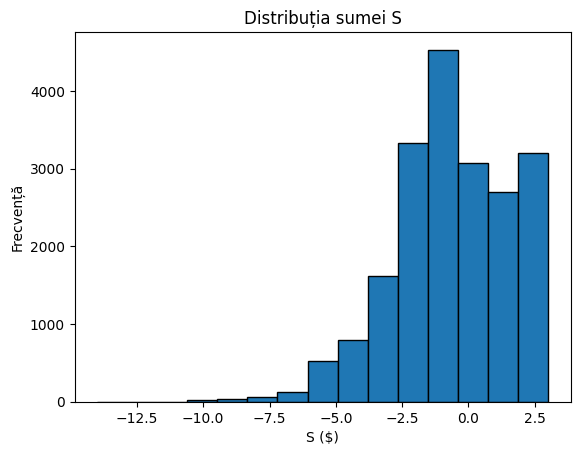

Cazul II: P(stema) = 0.7
Media lui S:  0.287


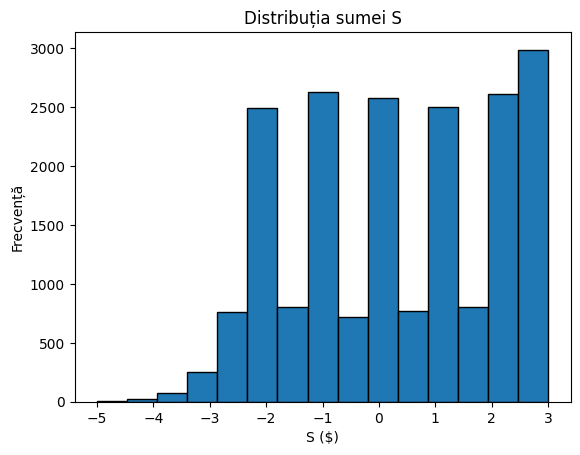

In [47]:
#EX 2. d)

print("Cazul I: P(stema) = 0.3")
lista_S = sim_jocuri(20000, p = 0.3)
print("Media lui S: ", calcul_medie(lista_S))
afis_hist(lista_S)


print("Cazul II: P(stema) = 0.7")
lista_S = sim_jocuri(20000, p = 0.7)
print("Media lui S: ", calcul_medie(lista_S))
afis_hist(lista_S)

Media estimată: 0.23005944766391626
Deviația standard estimată: 0.24823018874895916


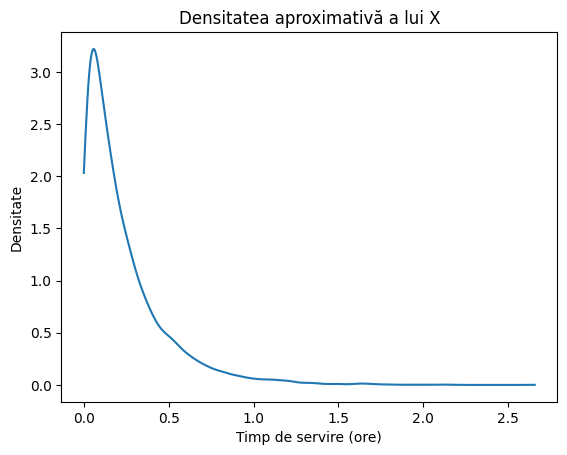

In [61]:
#EX 3

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

n = 10000

lambdas = [3, 6, 4]
probabilitati = [3/13, 6/13, 4/13]

X = []

for i in range(n):

    frizer = np.random.choice(3, p=probabilitati)
    lamb = lambdas[frizer]
    timp = np.random.exponential(scale=1/lamb)

    X.append(timp)

X = np.array(X)

print("Media estimată:", np.mean(X))
print("Deviația standard estimată:", np.std(X))

kde = gaussian_kde(X)
x = np.linspace(min(X), max(X), 500)
plt.plot(x, kde(x))
plt.xlabel("Timp de servire (ore)")
plt.ylabel("Densitate")
plt.title("Densitatea aproximativă a lui X")
plt.show()